# 01 | Dataset inventory

Member 1. All 80 training and 10 student-test trips; no evaluator data. Rebuild the inventory from raw files and verify the saved evidence.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/dataset_loader.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the PathSnap repository or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW = Path(os.environ.get("PATHSNAP_RAW_ROOT", str(ROOT / "data/raw")))
EVIDENCE = ROOT / "results/member1"
if not (EVIDENCE / "processing_summary.csv").exists():
    raise RuntimeError("Run python -m src.data.prepare_member1 first")
inventory = pd.read_csv(EVIDENCE / "dataset_inventory.csv", dtype={"trip_id": str})
summary = pd.read_csv(EVIDENCE / "processing_summary.csv", dtype={"trip_id": str})
display(inventory.groupby("partition").agg(trips=("trip_id", "size"), gps=("gps_observations", "sum")))

,trips,gps
partition,,
student_test,10,19160
train,80,208417


In [2]:
from src.data.trip_inventory import build_inventory
fresh = build_inventory(RAW)
fresh["trip_id"] = fresh.trip_id.astype(str)
pd.testing.assert_frame_equal(fresh.reset_index(drop=True), inventory.reset_index(drop=True), check_dtype=False)
display(fresh.groupby("partition")[["gps_observations", "nodes", "arcs", "route_arcs"]].sum())
assert fresh.groupby("partition").size().to_dict() == {"student_test": 10, "train": 80}
assert not fresh.trip_id.duplicated().any()
print("Inventory reproduced; trips do not overlap partitions.")

,gps_observations,nodes,arcs,route_arcs
partition,,,,
student_test,19160,90689,185041,3477
train,208417,1933485,3876904,31336


Inventory reproduced; trips do not overlap partitions.


,missing_values,invalid_coordinates,duplicate_timestamps,backward_timestamps,gaps_over_10s,reference_route_breaks,self_loops,duplicate_arcs
partition,,,,,,,,
student_test,0,0,0,0,27,1,2,128
train,0,0,0,0,590,13,22,1775


,partition,trip_id,gps_observations,nodes,arcs
44,train,00000054,19313,63822,116916
67,train,00000084,16031,24898,50888
16,train,00000021,15783,732,1510
73,train,00000092,7892,26468,53348
34,train,00000042,7739,49376,101128
1,train,00000002,7243,7936,16139
26,train,00000033,5844,3340,6360
78,train,00000098,5584,43440,88137
53,train,00000066,4325,9609,20071
65,train,00000082,4268,15696,31754


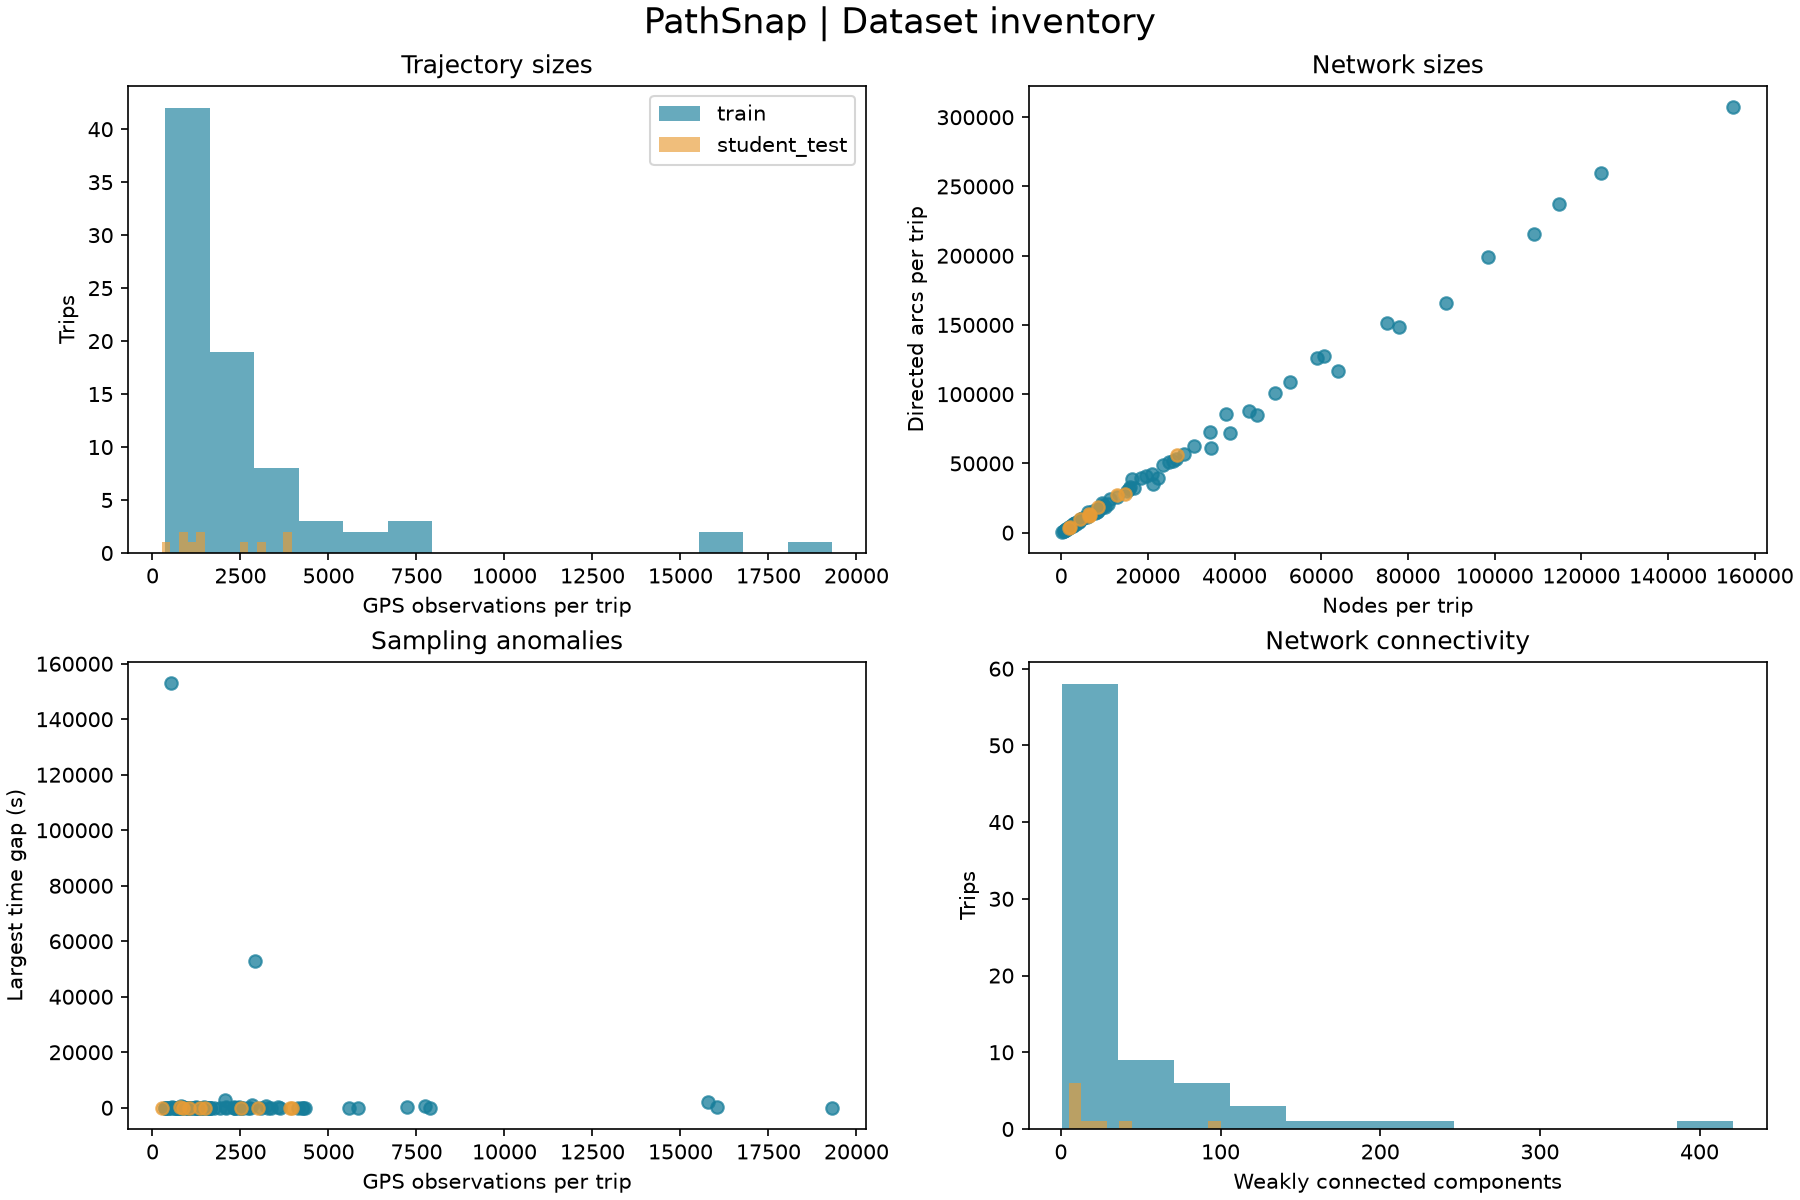

In [3]:
quality = ["missing_values", "invalid_coordinates", "duplicate_timestamps", "backward_timestamps",
           "gaps_over_10s", "reference_route_breaks", "self_loops", "duplicate_arcs"]
display(inventory.groupby("partition")[quality].sum())
display(inventory.nlargest(10, "gps_observations")[["partition", "trip_id", "gps_observations", "nodes", "arcs"]])
display(Image(filename=str(EVIDENCE / "dataset_overview.png")))

## Interpretation
Raw arc and node counts sum trip-local networks, which may overlap geographically. They are not counts of unique roads worldwide. A strict parser validates columns, numeric finiteness, integer IDs and index bounds; later preprocessing preserves observation IDs. Timestamp and network anomalies are reported rather than hidden.